# Estado del arte: por qué se eliminó el AMA, el debate sobre el SMA y la inestabilidad de colas pesadas

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 02 a 06 de este tema
- **Tiempo de lectura:** unos 45 minutos

## Objetivos

Al terminar este cuaderno puedes:

- explicar por qué el Comité de Basilea eliminó el Enfoque de Medición Avanzada (AMA) y lo reemplazó por el Enfoque de Medición Estándar (SMA), y qué argumentó la crítica académica al SMA;
- poner los dos enfoques lado a lado sobre las mismas historias versionadas de un banco sintético, para cuatro índices de cola y dos umbrales de recolección;
- leer, en números, las afirmaciones de que el SMA es insensible al perfil de riesgo y de que una distribución de pérdidas estimada cerca de un índice de cola de 1 es inestable;
- decir qué dicen y qué no dicen estos resultados sintéticos sobre bancos reales.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. El generador del caso C17 y sus estimadores viven en `data-pipeline/pipeline/cases/c17/`, que no es un paquete instalado: este cuaderno carga esos módulos por su ruta (importar todo el paquete `pipeline` importaría todos los casos y sus dependencias pesadas). La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
import sys
import types
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from riskvalidation.oprisk import distributions, sma

for name in ('riskvalidation', 'numpy', 'scipy', 'matplotlib'):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son las cuatro variantes del caso C17, una por índice de cola del banco sintético (0,6, 0,8, 0,96 y 1,1), cada una con 16 números para comparar: cuatro celdas (5 o 10 años de datos, umbral de recolección EUR 10.000 o 20.000) de 1.000 historias simuladas independientes, estimadas por la escalera LDA y por el SMA, frente a un cuantil anual de 99,9% verdadero y conocido.

- **Archivos que se leen:** `data/derived/C17/xi-0-6.json`, `xi-0-8.json`, `xi-0-96.json` y `xi-1-1.json`: `outputs.truth`, `outputs.cells[*].capital.lda_splice`, `outputs.cells[*].sma`, `outputs.bank` y `outputs.sma_response`, e `impact`.
- **Por qué el empalme:** entre los peldaños LDA, los lognormales son estables y muy sesgados (cuaderno 06), y los de aproximación y de escenarios son variantes del modelo de cola. El cuerpo lognormal con cola Pareto generalizada es el peldaño que defendería un modelador de riesgo operacional, y por eso es el que se contrasta con el SMA.
- **Qué es sintético:** el generador se calibra a medianas publicadas pero inventa el banco y sus pérdidas. Nada de lo que sigue mide un banco real.

La celda siguiente carga los documentos y el generador.

In [2]:
# Cargar los cuatro documentos de las variantes y el generador del caso por ruta
ROOT = Path("../../..").resolve()
docs = {name: json.loads((ROOT / "data" / "derived" / "C17" / (name + ".json")).read_text(encoding="utf-8")) for name in ("xi-0-6", "xi-0-8", "xi-0-96", "xi-1-1")}
sys.dont_write_bytecode = True
shell = types.ModuleType("c17")
shell.__path__ = [str(ROOT / "data-pipeline" / "pipeline" / "cases" / "c17")]
sys.modules["c17"] = shell
from c17 import generator

for name, doc in docs.items():
    print(name, "| cuantil de 99.9% verdadero de la pérdida anual (EUR):", format(doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"], ",.0f"), "| calculado por riskvalidation", doc["provenance"]["riskvalidation_version"])

xi-0-6 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 33,897,000 | calculado por riskvalidation 0.7.0
xi-0-8 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 163,483,000 | calculado por riskvalidation 0.7.0
xi-0-96 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 634,865,452 | calculado por riskvalidation 0.7.0
xi-1-1 | cuantil de 99.9% verdadero de la pérdida anual (EUR): 2,148,602,460 | calculado por riskvalidation 0.7.0


## Método

### Paso 1: ambos enfoques sobre las mismas historias

Para cada variante y celda el documento guarda, sobre las 1.000 historias, la razón del capital del empalme LDA con el cuantil verdadero (su mediana, su rango intercuartil sobre la verdad y la proporción de historias donde el peldaño está definido) y la razón del capital del SMA (el capital por riesgo operacional, ORC, del cuaderno 05) con el mismo cuantil verdadero. La celda siguiente imprime las 16 filas. El SMA se calcula en toda historia, así que siempre está definido; el empalme está definido solo donde converge su ajuste.

In [3]:
# Ambos enfoques contra el cuantil verdadero, en las 16 celdas de las cuatro variantes
print("%-8s %-10s | %-34s | %-30s" % ("", "", "LDA empalme: definido, mediana, RIC / verdad", "SMA: mediana, p25 - p75 sobre la verdad"))
for name, doc in docs.items():
    for cell in doc["outputs"]["cells"]:
        splice = cell["capital"]["lda_splice"]
        ratio = cell["sma"]["orc_over_true_quantile"]
        print("%-8s %-10s | %4d  %6.3f  %6.3f              | %6.3f   %6.3f - %6.3f" % (name, cell["id"], splice["n_defined"], splice["ratio_to_truth"]["median"], splice["iqr_over_truth"], ratio["median"], ratio["p25"], ratio["p75"]))

                    | LDA empalme: definido, mediana, RIC / verdad | SMA: mediana, p25 - p75 sobre la verdad
xi-0-6   y5-h10000  |  959   0.764   1.952              |  4.022    3.941 -  4.120
xi-0-6   y5-h20000  |  771   0.764   2.033              |  3.967    3.890 -  4.073
xi-0-6   y10-h10000 |  996   0.850   1.429              |  4.030    3.967 -  4.111
xi-0-6   y10-h20000 |  859   0.840   1.354              |  3.975    3.906 -  4.053
xi-0-8   y5-h10000  |  904   0.663   2.744              |  0.873    0.846 -  0.921
xi-0-8   y5-h20000  |  682   0.639   2.560              |  0.859    0.829 -  0.901
xi-0-8   y10-h10000 |  971   0.816   1.776              |  0.882    0.857 -  0.915
xi-0-8   y10-h20000 |  727   0.909   1.983              |  0.869    0.843 -  0.908
xi-0-96  y5-h10000  |  725   0.781   3.104              |  0.239    0.227 -  0.258
xi-0-96  y5-h20000  |  550   0.627   3.299              |  0.233    0.221 -  0.254
xi-0-96  y10-h10000 |  818   0.764   2.111              |  0.

### Paso 2: el SMA en el motor, sobre una historia por variante

El ORC del SMA depende de la historia solo a través de la pérdida anual promedio, y del banco solo a través de su indicador de negocio. Regeneramos la historia detrás de cada bloque de respuesta versionado y llamamos a `sma_capital` con el indicador de negocio del banco; la mediana versionada sobre 1.000 historias de la celda con 10 años y umbral de EUR 20.000 se imprime a su lado. El indicador de negocio del banco es el mismo en las cuatro variantes, así que toda diferencia del capital del SMA entre variantes viene solo de las pérdidas.

In [4]:
# El capital SMA de una historia regenerada por variante, junto a la mediana versionada de la celda
print("%-8s %16s %12s %12s | %16s" % ("", "pérdida anual promedio", "ILM", "ORC", "ORC mediano versionado"))
orc_single = {}
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10).recorded(20_000.0)
    result = sma.sma_capital(doc["outputs"]["bank"]["business_indicator"]["bi_eur"], history.annual)
    orc_single[name] = result.orc
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    print("%-8s %16s %12.4f %12s | %16s" % (name, format(history.annual.mean(), ",.0f"), result.ilm, format(result.orc, ",.0f"), format(cell["sma"]["orc_eur"]["median"], ",.0f")))

         pérdida anual promedio          ILM          ORC | ORC mediano versionado
xi-0-6          3,442,129       0.7355  132,388,684 |      134,743,278
xi-0-8          5,005,391       0.7953  143,154,295 |      142,003,392
xi-0-96         6,759,268       0.8544  153,800,481 |      151,571,436
xi-1-1          5,016,737       0.7957  143,227,478 |      165,036,744


### Paso 3: cuánto se mueve el capital cuando se mueve el perfil de riesgo

Entre las cuatro variantes el cuantil de 99,9% verdadero de la pérdida anual se multiplica por un factor grande, porque el índice de cola va de 0,6 a 1,1 con una frecuencia parecida. Una medida que siga al riesgo debería seguirlo. La celda siguiente imprime, para la celda con 10 años y umbral de EUR 20.000, el cuantil verdadero, el capital mediano del SMA y el capital mediano del empalme LDA, y el factor entre el mayor y el menor de cada uno.

In [5]:
# Cuantil verdadero, capital SMA mediano y capital mediano del empalme LDA en las cuatro variantes (10 años, umbral EUR 20.000)
rows = []
for name, doc in docs.items():
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    truth_q = doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"]
    rows.append((name, truth_q, cell["sma"]["orc_eur"]["median"], cell["capital"]["lda_splice"]["capital_eur"]["median"]))
    print("%-8s verdad %15s | SMA %15s | LDA empalme %15s" % (name, format(truth_q, ",.0f"), format(rows[-1][2], ",.0f"), format(rows[-1][3], ",.0f")))
for label, column in (("cuantil verdadero", 1), ("SMA", 2), ("LDA empalme", 3)):
    values = [r[column] for r in rows]
    print("%-24s mayor / menor: %.1f" % (label, max(values) / min(values)))

xi-0-6   verdad      33,897,000 | SMA     134,743,278 | LDA empalme      28,481,721
xi-0-8   verdad     163,483,000 | SMA     142,003,392 | LDA empalme     148,533,735
xi-0-96  verdad     634,865,452 | SMA     151,571,436 | LDA empalme     589,526,564
xi-1-1   verdad   2,148,602,460 | SMA     165,036,744 | LDA empalme   1,558,118,060
cuantil verdadero        mayor / menor: 63.4
SMA                      mayor / menor: 1.2
LDA empalme              mayor / menor: 54.7


### Paso 4: el índice de cola ajustado sobre una historia cerca de 1

El LDA necesita el índice de cola, y cerca de 1 es difícil de aprender. Sobre la historia de cada variante ajustamos la Pareto generalizada en los cuatro umbrales del cuaderno 02 con `tail_index_profile` e imprimimos las estimaciones y sus errores estándar. El índice verdadero de la última variante, 1,1, significa media infinita; que el ajustado quede sobre o bajo 1 depende de la muestra.

In [6]:
# Ajustar el perfil del índice de cola en la historia regenerada de cada variante
for name, doc in docs.items():
    block = doc["outputs"]["sma_response"]
    history = generator.draw_history(generator.variant(doc["outputs"]["tail_index"]), block["seed"], 10).recorded(20_000.0)
    profile = distributions.tail_index_profile(history.amounts, 20_000.0 * np.array([1.0, 2.0, 4.0, 8.0]))
    print("%-8s xi verdadero %-5s | xi_hat %s | se %s | estimaciones iguales o mayores a 1: %d" % (name, doc["outputs"]["tail_index"], np.round(profile.xi, 3), np.round(profile.xi_se, 3), int((profile.xi >= 1).sum())))

xi-0-6   xi verdadero 0.6   | xi_hat [0.588 0.468 0.501 0.378] | se [0.081 0.099 0.154 0.178] | estimaciones iguales o mayores a 1: 0
xi-0-8   xi verdadero 0.8   | xi_hat [0.936 0.845 0.745 0.681] | se [0.093 0.124 0.166 0.239] | estimaciones iguales o mayores a 1: 0
xi-0-96  xi verdadero 0.96  | xi_hat [1.02  0.963 1.029 0.87 ] | se [0.099 0.129 0.198 0.257] | estimaciones iguales o mayores a 1: 2
xi-1-1   xi verdadero 1.1   | xi_hat [0.956 0.947 1.04  0.89 ] | se [0.095 0.135 0.211 0.328] | estimaciones iguales o mayores a 1: 1


## Estado del arte

**Por qué se eliminó el AMA.** En su documento consultivo del 4 de marzo de 2016 el Comité de Basilea escribió que su revisión de las prácticas de modelación del riesgo operacional de los bancos y de los resultados de capital había revelado que la complejidad inherente del Enfoque de Medición Avanzada (AMA), y la falta de comparabilidad que surge de una amplia gama de prácticas internas de modelación, habían exacerbado la variabilidad de los cálculos de activos ponderados por riesgo y erosionado la confianza en los coeficientes de capital ponderados por riesgo. Propuso eliminar el AMA y basar el marco en un único método no basado en modelos, el Enfoque de Medición Estándar (BCBS, 2016). Las reformas finales están en Basilea III: Finalizando las reformas posteriores a la crisis (BCBS, 2017), y las reglas del enfoque estándar son el capítulo OPE25 del Marco de Basilea usado en el cuaderno 05.

**La crítica.** Peters, Shevchenko, Hassani y Chapelle (2016) discuten lo que llaman las debilidades y trampas del SMA, entre ellas la inestabilidad, la insensibilidad al riesgo y la superaditividad, y proponen mantener el marco de modelos internos AMA con recomendaciones de estandarización. Mignola, Ugoccioni y Cope (2016) publicaron comentarios a la propuesta del Comité en el mismo número de la revista.

**Qué es el enfoque de distribución de pérdidas (LDA).** La suma compuesta del cuaderno 01 con los bloques del cuaderno 02 (Chavez-Demoulin, Embrechts y Neslehova, 2006), calculada de forma exacta con la recursión de Panjer (1981) o la transformada rápida de Fourier y verificada frente a Shevchenko (2010) en el cuaderno 03, aproximada en forma cerrada en el cuaderno 04, y combinada con escenarios de expertos por credibilidad bayesiana en el cuaderno 05 (Shevchenko y Wuthrich, 2006). Para la aproximación de forma cerrada, la investigación detrás de este caso resume a Degen (2010) como un análisis por índice de cola que halla una zona problemática cerca de un índice de cola de 1; el texto primario no se volvió a leer para este cuaderno.

**Donde la investigación lee más de lo que dicen las fuentes.** La investigación detrás del caso presenta la inestabilidad de colas pesadas como un caso didáctico, construido sobre una calibración ilustrativa de las medianas de 2008 del Comité de Basilea (un índice de cola cercano a 0,96, con salvedades), y la lee como el tipo de inestabilidad que motivó el abandono del AMA. Esa lectura es de la propia investigación: el documento del Comité da la complejidad y la comparabilidad como sus razones. Este cuaderno no zanja la cuestión para bancos reales. Lo que agrega es una medición sobre un generador de verdad conocida: las dos celdas siguientes someten a los números versionados las dos afirmaciones de la crítica, la insensibilidad al riesgo del SMA y la inestabilidad del LDA.

In [7]:
# Poner dos afirmaciones de la literatura frente a los números versionados de la celda de 10 años y umbral de EUR 20.000
spread_truth, spread_sma, spread_lda, spread_lda_iqr = [], [], [], []
for name, doc in docs.items():
    cell = next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000")
    spread_truth.append(doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"])
    spread_sma.append(cell["sma"]["orc_eur"]["median"])
    spread_lda.append(cell["capital"]["lda_splice"]["ratio_to_truth"]["median"])
    spread_lda_iqr.append(cell["capital"]["lda_splice"]["iqr_over_truth"])
print("insensibilidad al riesgo: el SMA se mueve en un factor %.2f mientras el cuantil verdadero se mueve en %.1f" % (max(spread_sma) / min(spread_sma), max(spread_truth) / min(spread_truth)))
print("inestabilidad: el rango intercuartil del empalme LDA sobre la verdad es %s" % np.round(spread_lda_iqr, 2))
print("SMA / verdad por variante:", np.round(np.array(spread_sma) / np.array(spread_truth), 3), "| mediana empalme LDA / verdad:", np.round(spread_lda, 3))

insensibilidad al riesgo: el SMA se mueve en un factor 1.22 mientras el cuantil verdadero se mueve en 63.4
inestabilidad: el rango intercuartil del empalme LDA sobre la verdad es [1.35 1.98 2.23 2.32]
SMA / verdad por variante: [3.975 0.869 0.239 0.077] | mediana empalme LDA / verdad: [0.84  0.909 0.929 0.725]


La última celda dibuja la comparación. A la izquierda, en un eje logarítmico, el cuantil verdadero de cada variante, el capital mediano del SMA (casi plano) y la mediana del empalme LDA con su banda intercuartil entre historias (muy ancha). A la derecha, la razón de cada uno con la verdad en un eje lineal: el SMA pasa de varias veces la verdad a una fracción de ella al volverse más pesada la cola, y el LDA está centrado pero con una banda que es tan grande como la verdad.

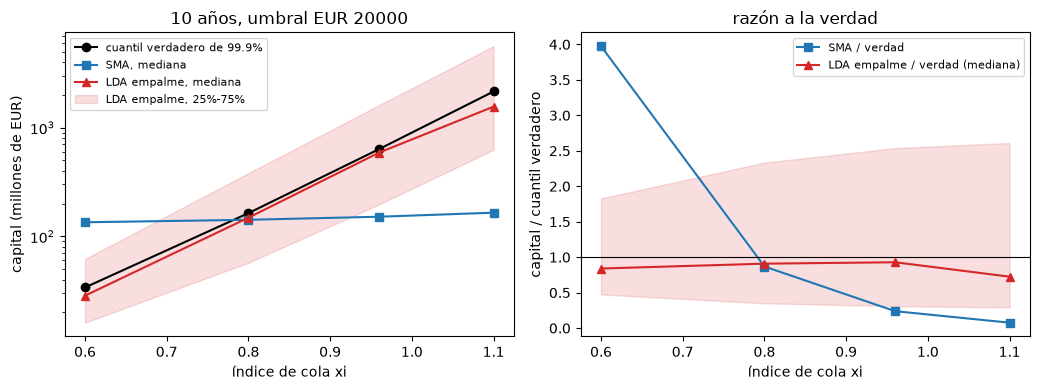

In [8]:
# Dibujar el cuantil verdadero, el SMA y el empalme LDA con su banda intercuartil en los cuatro índices de cola
xis = [doc["outputs"]["tail_index"] for doc in docs.values()]
cells = {name: next(c for c in doc["outputs"]["cells"] if c["id"] == "y10-h20000") for name, doc in docs.items()}
truths = np.array([doc["outputs"]["truth"]["annual_loss_quantile"]["value_eur"] for doc in docs.values()])
sma_median = np.array([cells[n]["sma"]["orc_eur"]["median"] for n in docs])
lda_p25 = np.array([cells[n]["capital"]["lda_splice"]["capital_eur"]["p25"] for n in docs])
lda_median = np.array([cells[n]["capital"]["lda_splice"]["capital_eur"]["median"] for n in docs])
lda_p75 = np.array([cells[n]["capital"]["lda_splice"]["capital_eur"]["p75"] for n in docs])
fig, (left, right) = plt.subplots(1, 2, figsize=(10.5, 4.0))
left.semilogy(xis, truths / 1e6, "ko-", label="cuantil verdadero de 99.9%")
left.semilogy(xis, sma_median / 1e6, "s-", color="tab:blue", label="SMA, mediana")
left.semilogy(xis, lda_median / 1e6, "^-", color="tab:red", label="LDA empalme, mediana")
left.fill_between(xis, lda_p25 / 1e6, lda_p75 / 1e6, color="tab:red", alpha=0.15, label="LDA empalme, 25%-75%")
left.set_xlabel("índice de cola xi")
left.set_ylabel("capital (millones de EUR)")
left.set_title("10 años, umbral EUR 20000")
left.legend(fontsize=8)
right.plot(xis, sma_median / truths, "s-", color="tab:blue", label="SMA / verdad")
right.plot(xis, lda_median / truths, "^-", color="tab:red", label="LDA empalme / verdad (mediana)")
right.fill_between(xis, lda_p25 / truths, lda_p75 / truths, color="tab:red", alpha=0.15)
right.axhline(1.0, color="black", linewidth=0.8)
right.set_xlabel("índice de cola xi")
right.set_ylabel("capital / cuantil verdadero")
right.set_title("razón a la verdad")
right.legend(fontsize=8)
fig.tight_layout()
plt.show()

## Resultados

- **Lado a lado.** En las 16 celdas, el SMA es angosto y el empalme LDA es ancho. El rango intercuartil del SMA sobre la verdad está entre 0,015 y 0,183, mientras el empalme tiene un rango entre 1,35 y 3,30 veces la verdad. El empalme está definido en 128 a 996 de las 1.000 historias, menos con índice de cola 1,1 y umbral de EUR 10.000 con 10 años.
- **Insensibilidad al riesgo.** Con 10 años y umbral de EUR 20.000 el cuantil de 99,9% verdadero crece en un factor de 63,4 entre los índices de cola 0,6 y 1,1 (de EUR 33,9 millones a EUR 2,15 mil millones), el empalme LDA mediano en 54,7, y el SMA mediano solo en 1,2 (de EUR 134,7 millones a EUR 165,0 millones). El SMA es 3,98 veces la verdad con índice de cola 0,6, 0,87 con 0,8, 0,24 con 0,96 y 0,077 con 1,1: sobrestima una cola liviana y subestima una pesada. El SMA no está calibrado al cuantil de 99,9% de ningún banco (el documento lo dice), así que estas razones son una comparación, no un error del SMA.
- **Inestabilidad.** El rango intercuartil del empalme sobre la verdad es 1,35, 1,98, 2,23 y 2,32 en los cuatro índices de cola: para un banco con diez años de datos, el capital LDA de dos bancos del mismo riesgo verdadero difiere casi tanto como el riesgo mismo. Las medianas están cerca de la verdad (0,84, 0,91, 0,93 y 0,73 veces ella), así que el LDA no se aleja en promedio y se aleja mucho en cualquier historia.
- **Cerca de 1.** En una sola historia regenerada el índice de cola ajustado en cuatro umbrales es 1,02, 0,96, 1,03 y 0,87 donde la verdad es 0,96, así que dos de cuatro estimaciones cruzan la línea de media finita, y 0,96, 0,95, 1,04 y 0,89 donde la verdad es 1,1, así que tres de cuatro estimaciones dicen que la media es finita cuando no lo es. Errores estándar de 0,10 a 0,33 lo explican.
- **Una historia.** El SMA de la historia única regenerada queda cerca de la mediana versionada en tres variantes (EUR 132,4 millones frente a 134,7 millones, EUR 143,2 millones frente a 142,0 millones, EUR 153,8 millones frente a 151,6 millones) y 13% bajo ella con índice de cola 1,1 (EUR 143,2 millones frente a 165,0 millones), donde unas pocas pérdidas grandes mueven el promedio de diez años.
- **Qué dice esto de bancos reales.** Nada directamente: el banco es sintético y el generador es la única verdad. Dice que las dos afirmaciones de la crítica, un SMA que sigue muy poco al riesgo y un LDA inestable con los largos de datos y los índices de cola que sugieren las estadísticas de Basilea, se cumplen para los estimadores y umbrales de este caso, y mide ambas con una verdad conocida.

Lo que este cuaderno no muestra: cómo depende la dispersión del capital LDA del largo de la historia y del índice de cola, medida con la prueba de estabilidad del motor sobre historias independientes (el cuaderno de nivel 4).

## Resumen

- El Comité de Basilea eliminó el AMA por su complejidad y la falta de comparabilidad de los modelos internos, y lo reemplazó por el SMA no basado en modelos; los críticos argumentaron que el SMA es insensible al riesgo e inestable.
- En un banco sintético de verdad conocida, el SMA cambia en un factor de 1,2 mientras el cuantil verdadero cambia en 63, y es 3,98 veces la verdad con una cola liviana y 0,077 con una pesada.
- La mediana del empalme LDA está cerca de la verdad pero su rango intercuartil es de 1,35 a 2,32 veces la verdad con diez años de datos; el índice de cola ajustado cerca de 1 cruza la línea de media finita solo por muestreo.
- Son mediciones sobre un generador, no afirmaciones sobre bancos reales, y el argumento de la inestabilidad como razón de la decisión de Basilea es la lectura de la investigación, no la del Comité.

**Qué probar a continuación.** Abre el documento `xi-0-96.json` e imprime las celdas de 5 años frente a las de 10 años para ver crecer la dispersión del empalme. Luego sigue con el cuaderno 08, que mide esa dispersión con la prueba de estabilidad del motor.

## Referencias

- BCBS (2016), Standardised Measurement Approach for operational risk, documento consultivo, 4 de marzo de 2016. https://www.bis.org/bcbs/publ/d355.htm
- BCBS (2017), Basel III: Finalising post-crisis reforms. https://www.bis.org/bcbs/publ/d424.htm
- BCBS, Basel Framework OPE25, Calculation of RWA for operational risk. https://www.bis.org/basel_framework/chapter/OPE/25.htm
- Peters, G. W., Shevchenko, P. V., Hassani, B. y Chapelle, A. (2016), Should the advanced measurement approach be replaced with the standardized measurement approach for operational risk?, Journal of Operational Risk 11(3). https://arxiv.org/abs/1607.02319
- Mignola, G., Ugoccioni, R. y Cope, E. (2016), Comments on the Basel Committee on Banking Supervision proposal for a new standardized approach for operational risk, Journal of Operational Risk 11(3), 51-69. https://doi.org/10.21314/JOP.2016.184
- Degen, M. (2010), The calculation of minimum regulatory capital using single-loss approximations, Journal of Operational Risk 5(4), 3-17. https://doi.org/10.21314/JOP.2010.084
- Chavez-Demoulin, V., Embrechts, P. y Neslehova, J. (2006), Quantitative models for operational risk: extremes, dependence and aggregation, Journal of Banking and Finance 30(10), 2635-2658. https://doi.org/10.1016/j.jbankfin.2005.11.008